# 01 · Análisis exploratorio y limpieza — Online Retail (UCI)

**Proyecto:** Segmentación avanzada de clientes · Inteligencia de Negocios y Minería de Datos

**Objetivo del notebook:** entender la estructura y la calidad del dataset de transacciones,
detectar los problemas que afectan a una segmentación **a nivel de cliente** y aplicar una
limpieza documentada (filas antes/después y justificación de cada paso).

**Dataset:** [Online Retail — UCI #352](https://archive.ics.uci.edu/dataset/352/online+retail).
Transacciones de un minorista online británico (regalos, mucho cliente mayorista) entre
2010-12-01 y 2011-12-09. Columnas: `InvoiceNo`, `StockCode`, `Description`, `Quantity`,
`InvoiceDate`, `UnitPrice`, `CustomerID`, `Country`.

> Toda la lógica vive en `src/segmentacion/` (carga, limpieza); este notebook solo la invoca y narra.
> Todos los números que aparecen en el texto salen de las celdas ejecutadas.

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
import seaborn as sns

from segmentacion import config
from segmentacion.carga import obtener_datos_crudos
from segmentacion.limpieza import es_cancelacion, es_codigo_no_producto, guardar, limpiar
from segmentacion.visualizacion import (COLOR_NEUTRO, COLOR_PRINCIPAL, COLOR_SECUNDARIO,
                                        DIAS_SEMANA, estilo, guardar_figura)

estilo()
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

crudo = obtener_datos_crudos()   # lee data/raw/online_retail.parquet (o descarga si no existe)
print(f"Filas: {len(crudo):,} · Columnas: {crudo.shape[1]}")

Filas: 541,909 · Columnas: 8


## 1. Estructura del dataset

In [2]:
crudo.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom


In [3]:
estructura = pd.DataFrame({
    "tipo": crudo.dtypes.astype(str),
    "valores_unicos": crudo.nunique(),
    "nulos": crudo.isna().sum(),
})
estructura

,tipo,valores_unicos,nulos
InvoiceNo,string,25900,0
StockCode,string,4070,0
Description,string,4211,1454
Quantity,int64,722,0
InvoiceDate,datetime64[us],23260,0
UnitPrice,float64,1630,0
CustomerID,Int64,4372,135080
Country,string,38,0


In [4]:
print("Rango de fechas:", crudo["InvoiceDate"].min(), "→", crudo["InvoiceDate"].max())
print(f"Facturas únicas: {crudo['InvoiceNo'].nunique():,}")
print(f"Productos (StockCode) únicos: {crudo['StockCode'].nunique():,}")
print(f"Clientes únicos: {crudo['CustomerID'].nunique():,}")
print(f"Países: {crudo['Country'].nunique()}")
crudo[["Quantity", "UnitPrice"]].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99])

Rango de fechas: 2010-12-01 08:26:00 → 2011-12-09 12:50:00
Facturas únicas: 25,900
Productos (StockCode) únicos: 4,070
Clientes únicos: 4,372
Países: 38


,Quantity,UnitPrice
count,"541,909.00","541,909.00"
mean,9.55,4.61
std,218.08,96.76
min,"-80,995.00","-11,062.06"
1%,-2.00,0.19
25%,1.00,1.25
50%,3.00,2.08
75%,10.00,4.13
99%,100.00,18.00
max,"80,995.00","38,970.00"


**Hallazgos — estructura**

- El dataset tiene **541.909 líneas de factura** (una fila = un producto dentro de una factura) y 8 columnas,
  desde el **01-12-2010 08:26** hasta el **09-12-2011 12:50**.
- Hay 25.900 facturas, 4.070 códigos de producto, 4.372 clientes identificados y 38 países.
- `Description` tiene **4.211** valores distintos frente a 4.070 `StockCode`: un mismo producto aparece con
  variantes de texto, así que para nombrar productos hay que agrupar por código, no por descripción.
- `Quantity` va de **-80.995 a 80.995** y `UnitPrice` de **-11.062,06 a 38.970**, pero sus medianas son 3 unidades
  y 2,08 £ (p99: 100 unidades y 18 £). Valores negativos y extremos enormes frente a una mediana pequeña: hay
  cancelaciones, ajustes contables y outliers que se investigan abajo.

## 2. Valores nulos

In [5]:
nulos = pd.DataFrame({"nulos": crudo.isna().sum(), "pct": 100 * crudo.isna().mean()})
nulos[nulos["nulos"] > 0]

,nulos,pct
Description,1454,0.27
CustomerID,135080,24.93


In [6]:
sin_cliente = crudo["CustomerID"].isna()
importe_crudo = crudo["Quantity"] * crudo["UnitPrice"]
ventas_pos = (~es_cancelacion(crudo)) & (importe_crudo > 0)

print(f"Líneas sin CustomerID: {sin_cliente.sum():,} ({100 * sin_cliente.mean():.2f} %)")
print(f"Facturas afectadas: {crudo.loc[sin_cliente, 'InvoiceNo'].nunique():,} de {crudo['InvoiceNo'].nunique():,}")
print(f"% del importe de ventas positivas sin cliente: "
      f"{100 * importe_crudo[ventas_pos & sin_cliente].sum() / importe_crudo[ventas_pos].sum():.2f} %")

# ¿Una factura mezcla líneas con y sin cliente?
mezcla = crudo.groupby("InvoiceNo")["CustomerID"].agg(lambda s: s.isna().any() and s.notna().any())
print(f"Facturas que mezclan líneas con y sin cliente: {int(mezcla.sum())}")

desc_nula = crudo["Description"].isna()
print(f"\nDescripción nula: {desc_nula.sum():,} líneas · con CustomerID: {crudo.loc[desc_nula, 'CustomerID'].notna().sum()} "
      f"· con precio 0: {(crudo.loc[desc_nula, 'UnitPrice'] == 0).sum():,}")

Líneas sin CustomerID: 135,080 (24.93 %)
Facturas afectadas: 3,710 de 25,900
% del importe de ventas positivas sin cliente: 16.46 %


Facturas que mezclan líneas con y sin cliente: 0

Descripción nula: 1,454 líneas · con CustomerID: 0 · con precio 0: 1,454


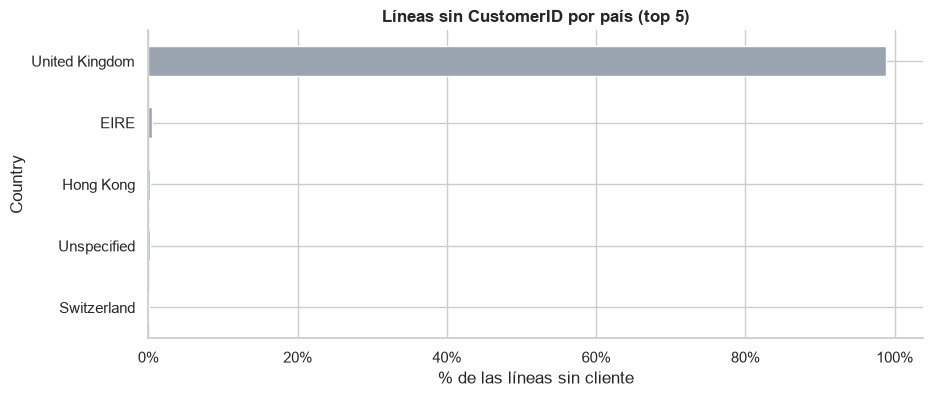

In [7]:
fig, ax = plt.subplots(figsize=(10, 4))
top_paises_sin = (crudo[sin_cliente]["Country"].value_counts(normalize=True).head(5) * 100)
top_paises_sin.plot.barh(ax=ax, color=COLOR_NEUTRO)
ax.invert_yaxis()
ax.xaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_title("Líneas sin CustomerID por país (top 5)")
ax.set_xlabel("% de las líneas sin cliente")
guardar_figura(fig, "01_sin_cliente_pais")
plt.show()

**Hallazgos — nulos**

- **CustomerID** falta en **135.080 líneas (24,93 %)**, repartidas en 3.710 facturas. Ninguna factura mezcla líneas
  con y sin cliente: el ID falta **por factura completa** (compras sin cliente registrado), no por un error puntual.
- Esas líneas suponen el **16,46 % del importe** de ventas positivas.
- **No se imputan**: no hay ninguna variable que permita inferir a qué cliente pertenece una factura, y la unidad de
  análisis es el cliente. Se eliminan, con una **limitación** que hay que declarar: la segmentación describe a los
  clientes registrados, no al 100 % de la facturación.
- `Description` falta en 1.454 líneas (0,27 %). **Todas** son sin CustomerID y con precio 0, así que desaparecen
  al quitar las filas sin cliente.

## 3. Duplicados

In [8]:
duplicadas = crudo.duplicated(keep=False)
print(f"Filas duplicadas exactas (sobrantes): {crudo.duplicated().sum():,}")
print(f"Filas implicadas (incluyendo la original): {duplicadas.sum():,}")
crudo[duplicadas].sort_values(["InvoiceNo", "StockCode"]).head(6)

Filas duplicadas exactas (sobrantes): 5,268
Filas implicadas (incluyendo la original): 10,147


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908,United Kingdom
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908,United Kingdom
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908,United Kingdom
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908,United Kingdom


**Hallazgos — duplicados**

- Hay **5.268 filas sobrantes** (10.147 implicadas contando la original) idénticas en las 8 columnas: misma factura,
  producto, cantidad, minuto y precio. Se interpretan como doble registro de la misma línea y se eliminan.
  Dejarlas inflaría la frecuencia y el gasto de los clientes afectados.

## 4. Cancelaciones (`InvoiceNo` que empieza por \"C\")

In [9]:
cancel = es_cancelacion(crudo)
prefijos = crudo["InvoiceNo"].str.extract(r"^([A-Za-z]*)")[0].replace("", "(numérica)")
display(prefijos.value_counts().rename_axis("prefijo").rename("lineas").to_frame())

print(f"Líneas de cancelación: {cancel.sum():,} ({100 * cancel.mean():.2f} %) · facturas: {crudo.loc[cancel, 'InvoiceNo'].nunique():,}")
print(f"Cancelaciones con Quantity > 0: {(cancel & (crudo['Quantity'] > 0)).sum()}")
print(f"Cancelaciones con CustomerID: {(cancel & crudo['CustomerID'].notna()).sum():,}")
print(f"Importe cancelado: {importe_crudo[cancel].sum():,.2f} · importe vendido (positivo): {importe_crudo[ventas_pos].sum():,.2f}")

,lineas
prefijo,
(numérica),532618
C,9288
A,3


Líneas de cancelación: 9,288 (1.71 %) · facturas: 3,836
Cancelaciones con Quantity > 0: 0
Cancelaciones con CustomerID: 8,905
Importe cancelado: -896,812.49 · importe vendido (positivo): 10,666,684.54


Las cantidades extremas del `describe()` (±80.995 y ±74.215) son simétricas. Veamos si se trata de
compras **anuladas** inmediatamente por el mismo cliente:

In [10]:
extremos = crudo[crudo["StockCode"].isin(["23843", "23166"]) & (crudo["Quantity"].abs() > 70_000)]
extremos[["InvoiceNo", "StockCode", "Description", "Quantity", "InvoiceDate", "UnitPrice", "CustomerID"]]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID
61619,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,2011-01-18 10:01:00,1.04,12346
61624,C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,2011-01-18 10:17:00,1.04,12346
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.08,16446
540422,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2011-12-09 09:27:00,2.08,16446


También hay anulaciones registradas **con el código manual `M`** en vez del producto original. El caso más
claro es el del cliente 15098: compra 60 cestas a un precio de 649,50 £ y 3 minutos después aparece
una cancelación `M` por el importe exacto.

In [11]:
crudo[crudo["CustomerID"] == 15098].sort_values("InvoiceDate")[["InvoiceNo", "StockCode", "Description", "Quantity", "InvoiceDate", "UnitPrice"]]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice
222670,556442,22502,PICNIC BASKET WICKER SMALL,60,2011-06-10 15:22:00,4.95
222680,556444,22502,PICNIC BASKET WICKER 60 PIECES,60,2011-06-10 15:28:00,649.50
222681,C556445,M,Manual,-1,2011-06-10 15:31:00,"38,970.00"
222682,556446,22502,PICNIC BASKET WICKER 60 PIECES,1,2011-06-10 15:33:00,649.50
222692,C556448,22502,PICNIC BASKET WICKER SMALL,-60,2011-06-10 15:39:00,4.95


In [12]:
facturas_A = crudo[prefijos == "A"]
facturas_A

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
299982,A563185,B,Adjust bad debt,1,2011-08-12 14:50:00,"11,062.06",<NA>,United Kingdom
299983,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,"-11,062.06",<NA>,United Kingdom
299984,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,"-11,062.06",<NA>,United Kingdom


**Hallazgos — cancelaciones y facturas especiales**

- Las facturas que empiezan por **"C"** son cancelaciones: **9.288 líneas (1,71 %)** en 3.836 facturas, 8.905 de ellas con
  cliente. **Todas** tienen `Quantity` negativa (0 casos con cantidad positiva), lo que confirma la regla de UCI.
- El importe cancelado (-896.812,49 £) equivale al **8,4 %** de lo vendido (10.666.684,54 £): no es despreciable y se
  aprovecha como señal de comportamiento (**tasa de devoluciones** en la Fase 2).
- **Los dos mayores outliers del dataset son compras anuladas.** El cliente 12346 compró 74.215 tarros y los canceló
  16 minutos después; el cliente 16446 compró 80.995 unidades y las canceló 12 minutos después. Si solo se quitaran las
  facturas "C", esas compras se quedarían como ventas reales y el cliente 12346 aparecería con 77.183,60 £ de gasto sin
  haber comprado nada. Por eso la limpieza **empareja cada cancelación con la compra que anula**.
- Algunas anulaciones se registran con el **código manual `M`**: el cliente 15098 compró 60 cestas a 649,50 £ (un
  precio que no corresponde a la cesta individual de 4,95 £) y 3 minutos después aparece una cancelación `M` por el
  importe exacto (38.970 £).
- Las 3 facturas **"A"** son ajustes contables de deuda incobrable (`B`, *Adjust bad debt*), sin cliente: no son ventas.

## 5. Cantidades y precios menores o iguales a cero

In [13]:
no_cancel = ~cancel
q_no_pos = no_cancel & (crudo["Quantity"] <= 0)
p_cero = crudo["UnitPrice"] == 0
p_neg = crudo["UnitPrice"] < 0

resumen_np = pd.DataFrame({
    "lineas": [q_no_pos.sum(), p_cero.sum(), p_neg.sum()],
    "con_CustomerID": [(q_no_pos & ~sin_cliente).sum(), (p_cero & ~sin_cliente).sum(), (p_neg & ~sin_cliente).sum()],
}, index=["Quantity <= 0 (sin ser cancelación)", "UnitPrice == 0", "UnitPrice < 0"])
resumen_np

,lineas,con_CustomerID
Quantity <= 0 (sin ser cancelación),1336,0
UnitPrice == 0,2515,40
UnitPrice < 0,2,0


In [14]:
print("Descripciones más frecuentes de las líneas con Quantity <= 0 que no son cancelación:")
crudo.loc[q_no_pos, "Description"].value_counts(dropna=False).head(10)

Descripciones más frecuentes de las líneas con Quantity <= 0 que no son cancelación:


Description
<NA>                      862
check                     120
damages                    45
damaged                    42
?                          41
sold as set on dotcom      20
Damaged                    14
thrown away                 9
Unsaleable, destroyed.      9
??                          7
Name: count, dtype: int64[pyarrow]

**Hallazgos — cantidades y precios no positivos**

- Hay **1.336 líneas con cantidad ≤ 0 que no son cancelaciones**, y **ninguna tiene CustomerID**. Sus descripciones
  ("damaged", "check", "thrown away", "?", "sold as set on dotcom", etc.) indican **ajustes internos de inventario**
  (mermas, roturas), no compras de clientes.
- Hay **2.515 líneas con precio 0** (solo 40 con cliente): regalos o ajustes sin valor monetario. Solo 2 líneas tienen
  precio negativo, que son los ajustes de deuda incobrable de las facturas "A".
- Conclusión: tras quitar las filas sin cliente, el filtro "cantidad y precio > 0" solo afecta a un puñado de filas,
  pero se mantiene como regla de validez de una venta.

## 6. Códigos que no son productos

Los productos tienen `StockCode` de 5 dígitos (a veces con una letra de variante, p. ej. `85123A`).
Listamos todos los códigos que **no** siguen ese patrón con su descripción para decidir, uno a uno,
cuáles no son mercancía.

In [15]:
no_patron = crudo[~crudo["StockCode"].str.match(r"^\d{5}")]
codigos = (no_patron.assign(importe=importe_crudo)
           .groupby("StockCode")
           .agg(descripcion=("Description", "first"), lineas=("Quantity", "size"),
                con_cliente=("CustomerID", "count"), importe=("importe", "sum"))
           .assign(excluido=lambda d: es_codigo_no_producto(d.index.to_series()))
           .sort_values("lineas", ascending=False))
codigos

,descripcion,lineas,con_cliente,importe,excluido
StockCode,,,,,
POST,POSTAGE,1256,1196,"66,230.64",True
DOT,DOTCOM POSTAGE,710,16,"206,245.48",True
M,Manual,571,465,"-68,674.19",True
C2,CARRIAGE,144,134,"6,986.00",True
D,Discount,77,77,"-5,696.22",True
S,SAMPLES,63,0,"-3,049.39",True
BANK CHARGES,Bank Charges,37,12,"-7,175.64",True
AMAZONFEE,AMAZON FEE,34,0,"-221,520.50",True
CRUK,CRUK Commission,16,16,"-7,933.43",True


In [16]:
print("Excluidos por ser no-producto:", sorted(codigos[codigos["excluido"]].index))
print("Se mantienen (son productos reales del 'dotcom gift shop' o similares):",
      sorted(codigos[~codigos["excluido"]].index))

Excluidos por ser no-producto: ['AMAZONFEE', 'B', 'BANK CHARGES', 'C2', 'CRUK', 'D', 'DOT', 'M', 'POST', 'S', 'gift_0001_10', 'gift_0001_20', 'gift_0001_30', 'gift_0001_40', 'gift_0001_50', 'm']
Se mantienen (son productos reales del 'dotcom gift shop' o similares): ['DCGS0003', 'DCGS0004', 'DCGS0055', 'DCGS0057', 'DCGS0066P', 'DCGS0067', 'DCGS0068', 'DCGS0069', 'DCGS0070', 'DCGS0071', 'DCGS0072', 'DCGS0073', 'DCGS0074', 'DCGS0076', 'DCGSSBOY', 'DCGSSGIRL', 'PADS']


**Hallazgos — códigos que no son productos**

La lista **no se ha copiado de ningún sitio**: sale de revisar la descripción de cada código que no sigue el patrón de
5 dígitos.
- **Se excluyen (16 códigos):** `POST` / `DOT` / `C2` (portes y transporte), `M` / `m` (ajustes manuales), `D` (descuentos),
  `S` (muestras), `BANK CHARGES`, `AMAZONFEE` y `CRUK` (comisiones y cargos), `B` (deuda incobrable) y los bonos
  `gift_0001_*`. Por ejemplo, `AMAZONFEE` suma -221.520,50 £ y `DOT` 206.245,48 £: son movimientos contables o
  logísticos, no compras de mercancía, y distorsionarían el gasto y el ticket promedio.
- **Se mantienen:** los `DCGS*` (bolsas de fiesta, collares para perro, lámparas) y `PADS` (*pads to match all cushions*).
  Son mercancía real con código atípico. Casi todos van sin cliente y se eliminan igualmente por esa razón.

## 7. Limpieza documentada

Orden de los pasos y razón del orden:

1. **Duplicados exactos** primero, para no contar dos veces nada de lo que sigue.
2. **Sin CustomerID**: la segmentación es por cliente; además concentra casi todas las anomalías
   (cantidades negativas "damaged", descripciones nulas, precios 0).
3. **Códigos no producto**: se quitan *antes* de separar cancelaciones para que las devoluciones
   guardadas sean solo de mercancía.
4. **Separar cancelaciones**: no se tiran, se guardan en `devoluciones.parquet`.
5. **Cantidad o precio ≤ 0** residuales.
6. **Compras anuladas**: compra revertida por una cancelación posterior del mismo cliente, mismo
   producto, misma cantidad y mismo precio (emparejamiento 1 a 1 con la compra más reciente).
   Corrige casos como el pedido de 80.995 unidades anulado 12 minutos después. Además, una
   cancelación manual (`M`) anula una compra si es del mismo cliente, por el **mismo importe exacto** y
   dentro de las 24 h siguientes (regla conservadora: las coincidencias por importe más lejanas en el
   tiempo son ambiguas y se parecen más a notas de crédito).

**Diciembre de 2011** (solo hasta el día 9) **no se elimina**: son las compras más recientes y
quitarlas sesgaría la *Recency*. Se tiene en cuenta marcándolo como mes incompleto en los
análisis temporales.

In [17]:
res = limpiar(crudo)
guardar(res)   # data/processed/: transacciones_limpias, devoluciones, bitacora_limpieza.csv
ventas, devoluciones, bitacora = res.ventas, res.devoluciones, res.bitacora
bitacora

,paso,filas_antes,filas_despues,filas_eliminadas,pct_eliminado,justificacion
0,1. Duplicados exactos,541909,536641,5268,0.97,Filas idénticas en todas las columnas: doble r...
1,2. Sin CustomerID,536641,401604,135037,25.16,La unidad de análisis es el cliente; sin ID la...
2,3. Códigos que no son producto,401604,399693,1911,0.48,"Portes, comisiones, descuentos, ajustes manual..."
3,4. Separar cancelaciones (factura 'C'),399693,391187,8506,2.13,Las cancelaciones no son compras; se guardan a...
4,5. Cantidad o precio <= 0,391187,391153,34,0.01,Una venta válida requiere cantidad y precio po...
5,6. Compras anuladas por cancelación posterior,391153,388422,2731,0.70,Compra revertida después por el mismo cliente:...


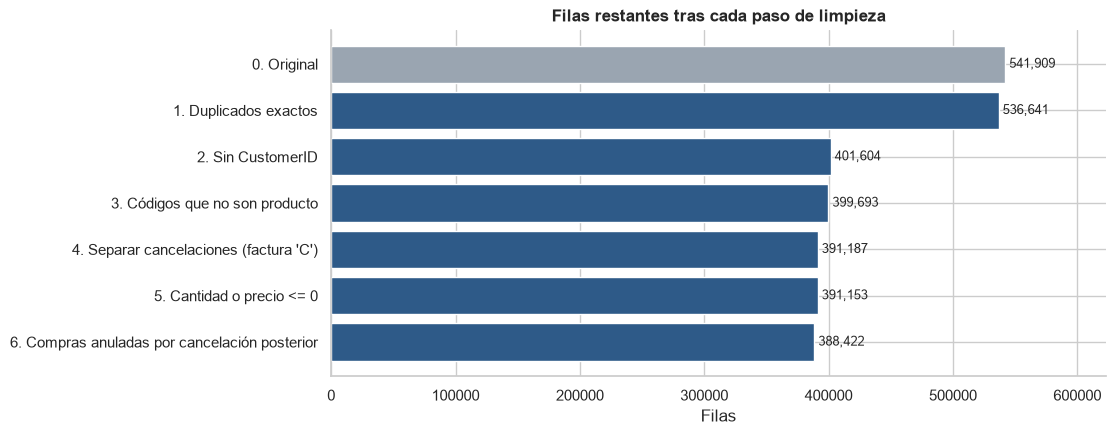

In [18]:
fig, ax = plt.subplots(figsize=(10, 4.5))
etiquetas = ["0. Original"] + bitacora["paso"].tolist()
filas = [bitacora["filas_antes"].iloc[0]] + bitacora["filas_despues"].tolist()
barras = ax.barh(etiquetas, filas, color=[COLOR_NEUTRO] + [COLOR_PRINCIPAL] * len(bitacora))
ax.invert_yaxis()
ax.bar_label(barras, labels=[f"{f:,}" for f in filas], padding=3, fontsize=9)
ax.set_xlim(0, max(filas) * 1.15)
ax.set_title("Filas restantes tras cada paso de limpieza")
ax.set_xlabel("Filas")
guardar_figura(fig, "01_bitacora_limpieza")
plt.show()

In [19]:
def resumen(df: pd.DataFrame, importe: pd.Series) -> dict:
    return {"lineas": len(df), "facturas": df["InvoiceNo"].nunique(), "clientes": df["CustomerID"].nunique(),
            "productos": df["StockCode"].nunique(), "paises": df["Country"].nunique(),
            "importe_ventas": importe[importe > 0].sum()}

pd.DataFrame({"original": resumen(crudo, importe_crudo.where(ventas_pos, 0)),
              "limpio": resumen(ventas, ventas["Importe"])}).T

,lineas,facturas,clientes,productos,paises,importe_ventas
original,"541,909.00","25,900.00","4,372.00","4,070.00",38.00,"10,666,684.54"
limpio,"388,422.00","18,279.00","4,324.00","3,646.00",37.00,"8,312,251.80"


In [20]:
clientes_perdidos = set(crudo["CustomerID"].dropna().astype(int)) - set(ventas["CustomerID"])
print(f"Clientes con ID que desaparecen tras la limpieza: {len(clientes_perdidos)}")
print("(clientes cuyas únicas líneas eran cancelaciones, compras anuladas o códigos no producto)")
print(f"\nDevoluciones guardadas: {len(devoluciones):,} · emparejadas con su compra: {int(devoluciones['EmparejaCompra'].sum()):,}")
print(f"Clientes (del conjunto limpio) con al menos una devolución: "
      f"{devoluciones['CustomerID'].isin(ventas['CustomerID']).groupby(devoluciones['CustomerID']).any().sum():,}")

Clientes con ID que desaparecen tras la limpieza: 48
(clientes cuyas únicas líneas eran cancelaciones, compras anuladas o códigos no producto)

Devoluciones guardadas: 8,506 · emparejadas con su compra: 2,726
Clientes (del conjunto limpio) con al menos una devolución: 1,496


**Hallazgos — resultado de la limpieza**

| Métrica | Original | Limpio |
|---|---:|---:|
| Líneas | 541.909 | 388.422 |
| Facturas | 25.900 | 18.279 |
| Clientes | 4.372 | 4.324 |
| Productos | 4.070 | 3.646 |
| Importe de ventas (£) | 10.666.684,54 | 8.312.251,80 |

- El paso que más filas elimina es **sin CustomerID (135.037 filas, 25,16 %)**. El resto suma menos del 4,3 %.
- El paso 6 elimina **2.731 compras anuladas**: 2.726 por cancelación exacta y 5 por anulación manual `M` en menos de 24 h.
- **48 clientes desaparecen**: todas sus líneas eran cancelaciones, compras anuladas o códigos que no son producto
  (entre ellos el 12346 del pedido de 74.215 unidades).
- Se guardan **8.506 devoluciones** de producto (2.726 emparejadas con su compra). **1.496 clientes** del conjunto limpio
  tienen al menos una devolución, así que la tasa de devoluciones será una variable informativa.
- Archivos generados: `data/processed/transacciones_limpias.parquet`, `devoluciones.parquet` y `bitacora_limpieza.csv`.

## 8. Análisis temporal (datos limpios)

In [21]:
mensual = (ventas.set_index("InvoiceDate")
           .resample("MS")
           .agg({"Importe": "sum", "InvoiceNo": "nunique", "CustomerID": "nunique"})
           .rename(columns={"InvoiceNo": "facturas", "CustomerID": "clientes"}))
dias_dic = ventas.loc[ventas["InvoiceDate"] >= "2011-12-01", "InvoiceDate"].dt.normalize().nunique()
print(f"Diciembre 2011 contiene datos de {dias_dic} días hábiles distintos (hasta el {ventas['InvoiceDate'].max():%d-%m-%Y}).")
mensual

Diciembre 2011 contiene datos de 8 días hábiles distintos (hasta el 09-12-2011).


,Importe,facturas,clientes
InvoiceDate,,,
2010-12-01,"556,580.13",1386,883
2011-01-01,"457,502.65",975,737
2011-02-01,"439,447.15",988,756
2011-03-01,"575,942.05",1303,970
2011-04-01,"448,641.83",1130,849
2011-05-01,"652,058.77",1528,1051
2011-06-01,"605,505.12",1375,986
2011-07-01,"586,113.32",1314,945
2011-08-01,"626,637.72",1264,933


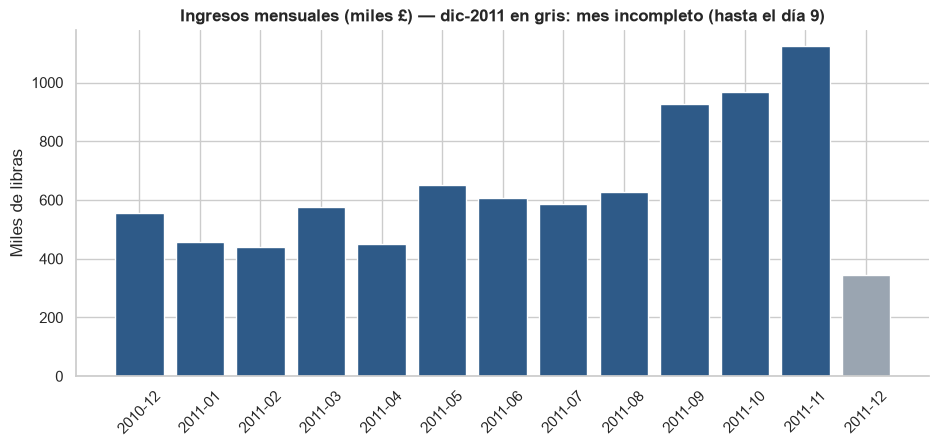

In [22]:
fig, ax = plt.subplots(figsize=(11, 4.5))
colores = [COLOR_NEUTRO if f == pd.Timestamp("2011-12-01") else COLOR_PRINCIPAL for f in mensual.index]
ax.bar(mensual.index.strftime("%Y-%m"), mensual["Importe"] / 1e3, color=colores)
ax.set_title("Ingresos mensuales (miles £) — dic-2011 en gris: mes incompleto (hasta el día 9)")
ax.set_ylabel("Miles de libras")
ax.tick_params(axis="x", rotation=45)
guardar_figura(fig, "01_ventas_mensuales")
plt.show()

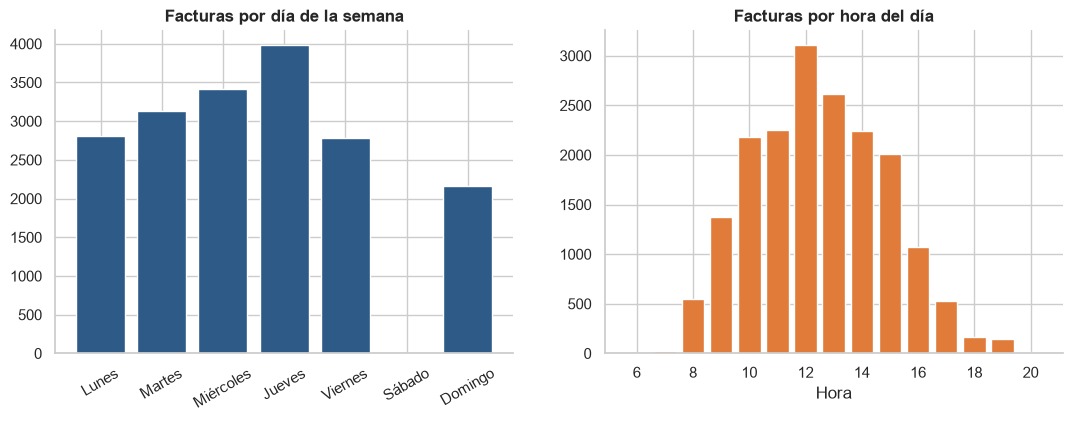

dia,Lunes,Martes,Miércoles,Jueves,Viernes,Sábado,Domingo
importe,"1,307,293.38","1,558,461.11","1,541,941.93","1,907,713.18","1,224,588.64",0.00,"772,253.56"
facturas,"2,806.00","3,133.00","3,416.00","3,979.00","2,785.00",0.00,"2,160.00"


Hora con más facturas: 12 · rango horario: 6 - 20


In [23]:
ventas_t = ventas.assign(dia=ventas["InvoiceDate"].dt.day_of_week, hora=ventas["InvoiceDate"].dt.hour)
por_dia = ventas_t.groupby("dia").agg(importe=("Importe", "sum"), facturas=("InvoiceNo", "nunique")).reindex(range(7), fill_value=0)
por_dia.index = por_dia.index.map(DIAS_SEMANA)
por_hora = ventas_t.groupby("hora").agg(importe=("Importe", "sum"), facturas=("InvoiceNo", "nunique"))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].bar(por_dia.index, por_dia["facturas"], color=COLOR_PRINCIPAL)
axes[0].set_title("Facturas por día de la semana")
axes[0].tick_params(axis="x", rotation=30)
axes[1].bar(por_hora.index, por_hora["facturas"], color=COLOR_SECUNDARIO)
axes[1].set_title("Facturas por hora del día")
axes[1].set_xlabel("Hora")
guardar_figura(fig, "01_dia_hora")
plt.show()
display(por_dia.T)
print("Hora con más facturas:", por_hora["facturas"].idxmax(), "· rango horario:", por_hora.index.min(), "-", por_hora.index.max())

**Hallazgos — temporal**

- **Estacionalidad de fin de año:** de enero a agosto de 2011 los ingresos mensuales están entre 439 mil y 652 mil £.
  Desde septiembre suben a 928 mil (sep), 969 mil (oct) y **1,12 millones en noviembre** (máximo). Diciembre de 2010
  (556 mil £) también está por encima de los meses de principios de año. Es coherente con un mayorista de regalos que se
  abastece para Navidad. Con un solo año completo no se puede separar del todo la estacionalidad del crecimiento del
  negocio, y así se declara como limitación.
- **Diciembre de 2011 está incompleto** (8 días con ventas, hasta el 09-12). Sus 342.871 £ **no son una caída**; por eso
  se dibuja en gris. Para RFM se conserva.
- **No hay ventas en sábado** (0 facturas). El jueves es el día más fuerte (3.979 facturas) y el domingo el más débil de
  los días con actividad (2.160).
- Las compras ocurren entre las **6 y las 20 h**, con pico a las **12 h**.
- Horario laboral, ningún sábado y pedidos grandes: la clientela es en buena parte **B2B** (tiendas y mayoristas), lo que
  explica las colas largas en cantidades y gasto.

## 9. Países

In [24]:
paises = (ventas.groupby("Country")
          .agg(importe=("Importe", "sum"), clientes=("CustomerID", "nunique"), facturas=("InvoiceNo", "nunique"))
          .sort_values("importe", ascending=False))
paises["pct_importe"] = 100 * paises["importe"] / paises["importe"].sum()
paises["pct_clientes"] = 100 * paises["clientes"] / ventas["CustomerID"].nunique()
paises.head(10)

,importe,clientes,facturas,pct_importe,pct_clientes
Country,,,,,
United Kingdom,"6,839,041.47",3909,16471,82.28,90.40
Netherlands,"283,479.54",9,93,3.41,0.21
EIRE,"247,812.07",3,253,2.98,0.07
Germany,"203,961.43",94,443,2.45,2.17
France,"182,143.53",87,377,2.19,2.01
Australia,"137,124.05",9,53,1.65,0.21
Switzerland,"52,093.80",21,46,0.63,0.49
Spain,"52,029.97",29,87,0.63,0.67
Japan,"37,314.37",8,19,0.45,0.19


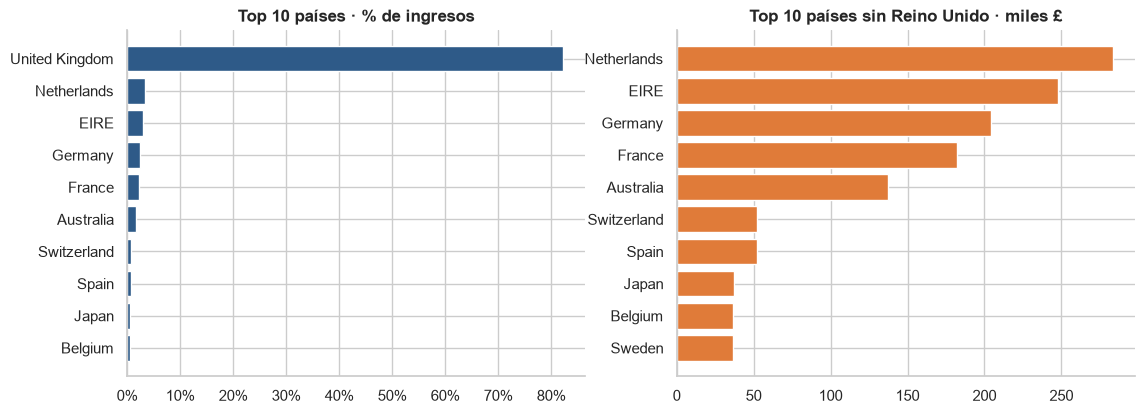

In [25]:
top = paises.head(10).iloc[::-1]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].barh(top.index, top["pct_importe"], color=COLOR_PRINCIPAL)
axes[0].set_title("Top 10 países · % de ingresos")
axes[0].xaxis.set_major_formatter(mtick.PercentFormatter())
sin_uk = paises.drop(index="United Kingdom").head(10).iloc[::-1]
axes[1].barh(sin_uk.index, sin_uk["importe"] / 1e3, color=COLOR_SECUNDARIO)
axes[1].set_title("Top 10 países sin Reino Unido · miles £")
guardar_figura(fig, "01_paises")
plt.show()

**Hallazgos — países**

- **Reino Unido** concentra el **90,40 % de los clientes** (3.909) y el **82,28 % de los ingresos**.
- Fuera del Reino Unido, los ingresos los mueven **pocos clientes muy grandes**: Países Bajos aporta el 3,41 % con solo
  **9 clientes** y EIRE (Irlanda) el 2,98 % con **3 clientes**, mientras Alemania (94 clientes) y Francia (87) tienen más
  clientes pero menos ingresos.
- **Decisión:** el país **no se usará como variable de clustering**. Con un 90 % de clientes en una sola categoría, aporta
  poca información y forzaría segmentos geográficos. Se usará en el **perfilamiento** (país dominante por segmento).

## 10. Productos

In [26]:
# Un mismo StockCode puede tener variantes de descripción: se usa la más frecuente.
desc_moda = ventas.groupby("StockCode")["Description"].agg(lambda s: s.mode().iat[0] if s.notna().any() else "")
productos = (ventas.groupby("StockCode")
             .agg(unidades=("Quantity", "sum"), importe=("Importe", "sum"), clientes=("CustomerID", "nunique"))
             .join(desc_moda.rename("descripcion")))
print(f"StockCode con más de una descripción: {(ventas.groupby('StockCode')['Description'].nunique() > 1).sum()}")
top_imp = productos.nlargest(10, "importe")
top_uni = productos.nlargest(10, "unidades")
display(top_imp)
display(top_uni)

StockCode con más de una descripción: 207


,unidades,importe,clientes,descripcion
StockCode,,,,
22423,12032,"138,375.85",873,REGENCY CAKESTAND 3 TIER
85123A,34239,"94,073.65",854,WHITE HANGING HEART T-LIGHT HOLDER
85099B,45197,"83,481.96",633,JUMBO BAG RED RETROSPOT
47566,15087,"67,954.83",708,PARTY BUNTING
84879,35234,"56,364.02",677,ASSORTED COLOUR BIRD ORNAMENT
23084,27123,"51,188.84",449,RABBIT NIGHT LIGHT
79321,9569,"45,930.36",204,CHILLI LIGHTS
22086,15184,"41,543.48",611,PAPER CHAIN KIT 50'S CHRISTMAS
21137,11389,"39,000.80",139,BLACK RECORD COVER FRAME


,unidades,importe,clientes,descripcion
StockCode,,,,
84077,54175,"13,516.65",305,WORLD WAR 2 GLIDERS ASSTD DESIGNS
22197,48938,"37,044.18",406,POPCORN HOLDER
85099B,45197,"83,481.96",633,JUMBO BAG RED RETROSPOT
84879,35234,"56,364.02",677,ASSORTED COLOUR BIRD ORNAMENT
85123A,34239,"94,073.65",854,WHITE HANGING HEART T-LIGHT HOLDER
21212,33574,"16,329.08",632,PACK OF 72 RETROSPOT CAKE CASES
23084,27123,"51,188.84",449,RABBIT NIGHT LIGHT
22492,25932,"15,945.64",211,MINI PAINT SET VINTAGE
22616,25317,"7,257.09",194,PACK OF 12 LONDON TISSUES


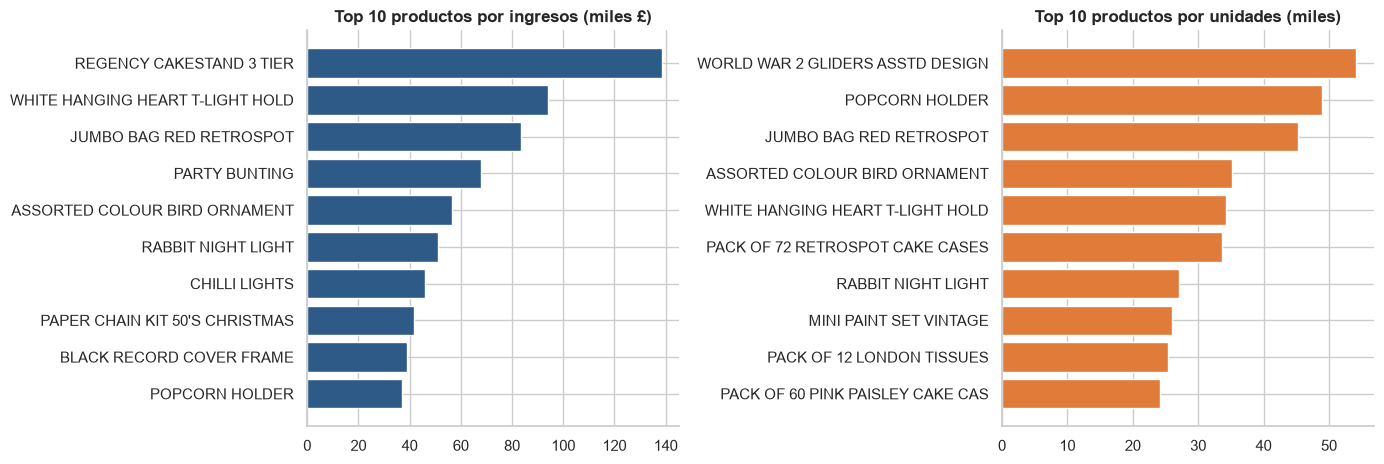

Productos que generan el 80 % de los ingresos: 804 de 3,646 (22.1 %)


In [27]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, datos, col, titulo, color in [(axes[0], top_imp, "importe", "Top 10 productos por ingresos (miles £)", COLOR_PRINCIPAL),
                                      (axes[1], top_uni, "unidades", "Top 10 productos por unidades (miles)", COLOR_SECUNDARIO)]:
    d = datos.iloc[::-1]
    ax.barh(d["descripcion"].str.slice(0, 32), d[col] / 1e3, color=color)
    ax.set_title(titulo)
fig.tight_layout()
guardar_figura(fig, "01_productos")
plt.show()

concentracion = productos["importe"].sort_values(ascending=False).cumsum() / productos["importe"].sum()
print(f"Productos que generan el 80 % de los ingresos: {(concentracion <= 0.80).sum() + 1:,} de {len(productos):,} "
      f"({100 * ((concentracion <= 0.80).sum() + 1) / len(productos):.1f} %)")

**Hallazgos — productos**

- 207 códigos tienen más de una descripción; se nombra cada producto con su descripción más frecuente.
- El producto con más ingresos es **REGENCY CAKESTAND 3 TIER** (138.375,85 £, comprado por 873 clientes). El de más
  unidades es **WORLD WAR 2 GLIDERS ASSTD DESIGNS** (54.175 unidades, pero solo 13.516,65 £): artículos baratos vendidos
  en volumen frente a artículos de mayor precio.
- **Concentración tipo Pareto:** 804 de 3.646 productos (**22,1 %**) generan el 80 % de los ingresos.
- Los productos top por segmento se usarán en la Fase 4 para el perfilamiento.

## 11. Distribuciones y outliers

In [28]:
facturas = ventas.groupby("InvoiceNo").agg(importe=("Importe", "sum"), unidades=("Quantity", "sum"), lineas=("StockCode", "size"))
clientes = ventas.groupby("CustomerID").agg(gasto=("Importe", "sum"), facturas=("InvoiceNo", "nunique"))

variables = {
    "Quantity (línea)": ventas["Quantity"],
    "UnitPrice (línea)": ventas["UnitPrice"],
    "Importe (línea)": ventas["Importe"],
    "Importe por factura": facturas["importe"],
    "Gasto total por cliente": clientes["gasto"],
    "Facturas por cliente": clientes["facturas"],
}

def outliers_iqr(s: pd.Series) -> int:
    q1, q3 = s.quantile([0.25, 0.75])
    return int((s > q3 + 1.5 * (q3 - q1)).sum())

dist = pd.DataFrame({n: {"n": len(s), "media": s.mean(), "mediana": s.median(), "p99": s.quantile(0.99),
                         "max": s.max(), "asimetria": s.skew(), "outliers_IQR": outliers_iqr(s),
                         "pct_outliers": 100 * outliers_iqr(s) / len(s)} for n, s in variables.items()}).T
dist

,n,media,mediana,p99,max,asimetria,outliers_IQR,pct_outliers
Quantity (línea),"388,422.00",12.66,6.00,120.00,"4,800.00",30.03,"25,239.00",6.50
UnitPrice (línea),"388,422.00",2.86,1.95,12.75,649.50,29.41,"32,205.00",8.29
Importe (línea),"388,422.00",21.40,11.90,199.20,"7,144.72",28.49,"30,027.00",7.73
Importe por factura,"18,279.00",454.74,300.66,"3,628.79","27,872.80",12.30,"1,434.00",7.85
Gasto total por cliente,"4,324.00","1,922.35",656.00,"17,235.09","278,778.02",21.50,416.00,9.62
Facturas por cliente,"4,324.00",4.23,2.00,29.77,203.00,11.84,275.00,6.36


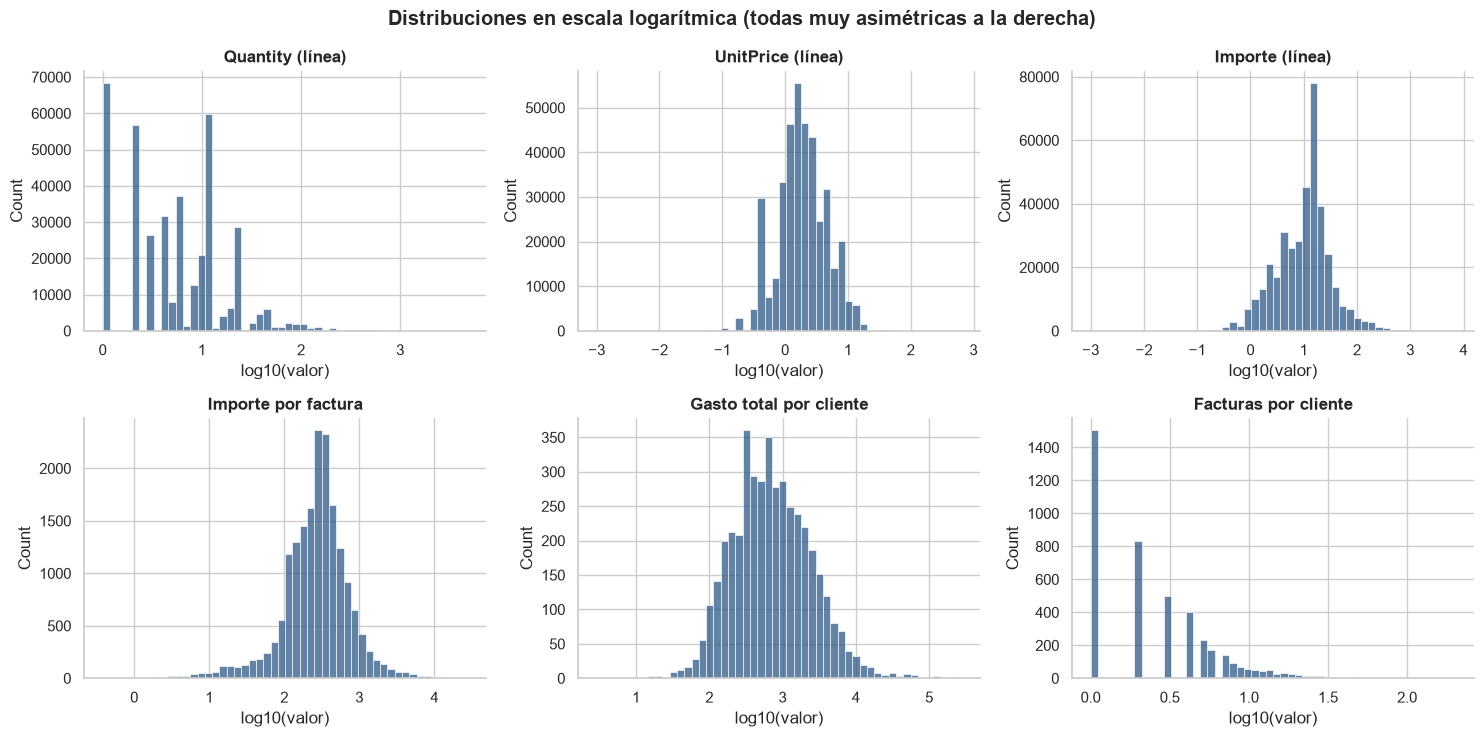

In [29]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7.5))
for ax, (nombre, s) in zip(axes.flat, variables.items()):
    sns.histplot(np.log10(s.clip(lower=s[s > 0].min())), bins=50, ax=ax, color=COLOR_PRINCIPAL)
    ax.set_title(nombre)
    ax.set_xlabel("log10(valor)")
fig.suptitle("Distribuciones en escala logarítmica (todas muy asimétricas a la derecha)", fontweight="bold")
fig.tight_layout()
guardar_figura(fig, "01_distribuciones_log")
plt.show()

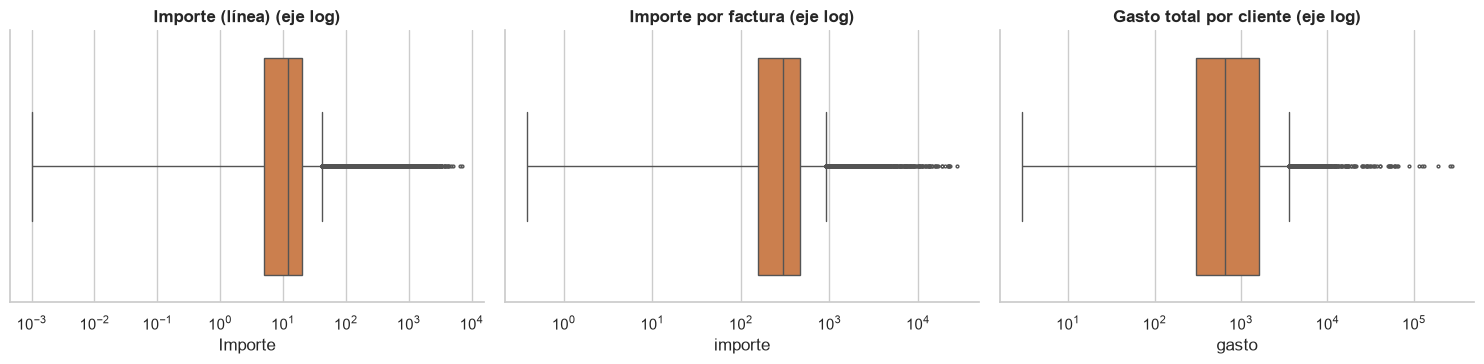

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, nombre in zip(axes, ["Importe (línea)", "Importe por factura", "Gasto total por cliente"]):
    sns.boxplot(x=variables[nombre], ax=ax, color=COLOR_SECUNDARIO, fliersize=2)
    ax.set_xscale("log")
    ax.set_title(f"{nombre} (eje log)")
fig.tight_layout()
guardar_figura(fig, "01_boxplots")
plt.show()

In [31]:
top_clientes = clientes.sort_values("gasto", ascending=False)
participacion = top_clientes["gasto"].cumsum() / top_clientes["gasto"].sum()
for pct in [1, 5, 10, 20]:
    k = int(np.ceil(len(top_clientes) * pct / 100))
    print(f"Top {pct:>2} % de clientes ({k:,}) concentra el {100 * participacion.iloc[k - 1]:.1f} % de los ingresos")
display(top_clientes.head(5).join(ventas.groupby("CustomerID")["Country"].first()))

Top  1 % de clientes (44) concentra el 30.2 % de los ingresos
Top  5 % de clientes (217) concentra el 48.7 % de los ingresos
Top 10 % de clientes (433) concentra el 60.0 % de los ingresos
Top 20 % de clientes (865) concentra el 73.7 % de los ingresos


,gasto,facturas,Country
CustomerID,,,
14646,"278,778.02",72,Netherlands
18102,"259,657.30",60,United Kingdom
17450,"189,607.53",45,United Kingdom
14911,"129,654.58",195,EIRE
12415,"123,806.88",19,Australia


**Hallazgos — distribuciones y outliers**

- **Todas las variables son fuertemente asimétricas a la derecha.** La asimetría va de 11,84 (facturas por cliente) a
  30,03 (cantidad por línea), y la media supera siempre a la mediana. Por ejemplo, el gasto por cliente tiene media de
  **1.922,35 £** y mediana de **656,00 £**, con un máximo de **278.778,02 £**.
- En escala logarítmica, el gasto por cliente y el importe por factura quedan **aproximadamente simétricos**. Esto
  justifica aplicar `log1p` en la Fase 2, porque K-Means y GMM se apoyan en distancias euclídeas y en formas
  aproximadamente gaussianas.
- Por la regla IQR, entre el **6 % y el 10 %** de las observaciones de cada variable son outliers. Ya **no son errores**
  (las anulaciones, cargos y ajustes se quitaron en la limpieza): son **clientes mayoristas reales**. La línea más cara
  que queda (649,50 £) es 1 unidad de *PICNIC BASKET WICKER 60 PIECES*, un lote de 60 cestas.
- **Concentración de ingresos:** el **1 %** de los clientes (44) genera el **30,2 %** de los ingresos, el 5 % el 48,7 %, el
  10 % el 60,0 % y el 20 % el 73,7 %. Los 5 mayores clientes superan cada uno los 120 mil £ (Países Bajos, Reino Unido,
  EIRE y Australia).
- **Implicación:** borrar estos clientes eliminaría a los más valiosos para el negocio. En la Fase 2 se decidirá su
  tratamiento (log, escalador robusto, winsorizado o segmento aparte) comparando opciones con datos.

## 12. Conclusiones del EDA y decisiones para la Fase 2

**Resumen de lo aprendido**

1. **Calidad:** el principal problema es el 24,93 % de líneas sin CustomerID (16,46 % del importe). Se excluyen
   porque no se pueden asignar a ningún cliente, y queda declarado como limitación.
2. **Cancelaciones:** no basta con borrar las facturas "C". Hay que anular también la compra original, incluidas las
   anulaciones manuales `M`. Si no, aparecen "clientes" de decenas de miles de libras que en realidad no compraron.
3. **Base final:** **388.422 líneas · 18.279 facturas · 4.324 clientes · 8.312.251,80 £**.
4. **Negocio:** mayorista de regalos con clientela B2B, concentrado en Reino Unido, muy estacional (pico en noviembre)
   y con ingresos muy concentrados (el 1 % de clientes genera el 30,2 %).

**Decisiones que pasan a la Fase 2 (ingeniería de características)**

- **Fecha de referencia para Recency** = última fecha del dataset (09-12-2011) + 1 día = **10-12-2011**.
- Variables a nivel de cliente calculadas sobre `transacciones_limpias.parquet`. La **tasa de devoluciones**, sobre
  `devoluciones.parquet`.
- **Transformación `log1p`** por la fuerte asimetría, y comparación de StandardScaler frente a RobustScaler.
- Los **mayoristas no se eliminan a ciegas**: se comparará su tratamiento con datos.
- **País** fuera del clustering; se usa en el perfilamiento.